Logistic regression finds *a* line that separates the classes. When several lines all
achieve zero errors, nothing in its loss prefers one over another.

The support vector machine adds the missing criterion: **pick the line with the widest
margin**. Formally, maximise the distance to the nearest point of either class:

$$\max_{\mathbf{w},b} \; \frac{2}{\lVert\mathbf{w}\rVert}
\quad\text{subject to}\quad y_i(\mathbf{w}^\top\mathbf{x}_i + b) \ge 1$$

Two consequences follow, and both are visible in the numbers below:

1. Only the points **on** the margin matter. Everything else could be deleted without
   changing the answer &mdash; those few points are the *support vectors*.
2. The optimisation depends on the data only through **inner products**
   $\mathbf{x}_i^\top\mathbf{x}_j$. Replace that product with a kernel and the same
   algorithm draws curved boundaries in the original space without ever computing
   coordinates there.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
np.set_printoptions(precision=4, suppress=True, linewidth=140)


def banner(title, ch="="):
    print(ch * 78)
    print(f"  {title}")
    print(ch * 78)


def step(label):
    print()
    print(label)
    print("=" * 78)


def check(manual, from_array, label="MATCH"):
    ok = np.allclose(manual, from_array)
    print(f"      = {manual:+.6f}   |  from array: {from_array:+.6f}   |  {label}: {ok}")
    return ok


def expand(u, v, per_line=4):
    """Write a dot product out term by term."""
    terms = [f"({a:+.4f})*({b:+.4f})" for a, b in zip(u, v)]
    lines, out = [], ""
    for i, t in enumerate(terms):
        out += t + (" + " if i < len(terms) - 1 else "")
        if (i + 1) % per_line == 0:
            lines.append(out); out = ""
    if out:
        lines.append(out)
    return "\n      ".join(lines)


def show_matrix(M, name="M", rows=None, cols=None, fmt="{:+8.3f}", max_cols=14):
    M = np.asarray(M)
    if M.ndim == 1:
        M = M[None, :]
    cut = M.shape[1] > max_cols
    Ms = M[:, :max_cols] if cut else M
    print(f"{name} {np.asarray(M).shape}" +
          (f"   [first {max_cols} of {M.shape[1]} columns]" if cut else "") + " =")
    if cols is not None:
        head = "".join(f"{str(c):>10}" for c in (cols[:max_cols] if cut else cols))
        print(" " * 13 + head)
    for r in range(Ms.shape[0]):
        lab = f"{str(rows[r]):>10} | " if rows is not None else f"{r:>10} | "
        print("   " + lab + "  ".join(fmt.format(v) for v in Ms[r]))


def show_matmul(A, B, C, na="A", nb="B", nc="C", i=0, j=0,
                rows_A=None, note=None, max_cols=14):
    """Print both operands of A @ B = C, then verify one element by hand."""
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{na} {A.shape}   @   {nb} {B.shape}   =   {nc} {C.shape}")
    print(f"  shape rule: ({A.shape[0]} x {A.shape[1]}) @ ({B.shape[0]} x {B.shape[1]})"
          f" -> ({A.shape[0]} x {B.shape[1]})   inner dim {A.shape[1]} cancels")
    if note:
        print(f"  {note}")
    print("=" * 78)
    print()
    show_matrix(A, na, rows_A, max_cols=max_cols)
    print()
    show_matrix(B, nb, max_cols=max_cols)
    print()
    show_matrix(C, nc, rows_A, max_cols=max_cols)
    print(f"\n  worked element  {nc}[{i},{j}]  =  row {i} of {na}  .  column {j} of {nb}")
    print(f"      row {i} of {na} = {np.round(A[i], 4)}")
    print(f"      col {j} of {nb} = {np.round(B[:, j], 4)}")
    print(f"      {expand(A[i], B[:, j])}")
    check(float(A[i] @ B[:, j]), float(C[i, j]))


def show_elementwise(A, B, C, na, nb, nc, op="+", rows=None):
    A, B, C = np.asarray(A), np.asarray(B), np.asarray(C)
    banner(f"{nc} = {na} {op} {nb}      all three are {A.shape} - element-wise")
    for r in range(A.shape[0]):
        lab = f"{rows[r]:>10}" if rows is not None else f"{r:>10}"
        print(f"\n{lab} |")
        print("   " + f"{na:>14}: " + "  ".join(f"{v:+8.3f}" for v in A[r]))
        print("   " + f"{nb:>14}: " + "  ".join(f"{v:+8.3f}" for v in B[r]))
        print("   " + f"{nc:>14}: " + "  ".join(f"{v:+8.3f}" for v in C[r]))
    print(f"\n  check [0,0]: {A[0,0]:+.6f} {op} {B[0,0]:+.6f} = {C[0,0]:+.6f}   "
          f"MATCH: {np.isclose(A[0,0] + B[0,0] if op == '+' else A[0,0] - B[0,0], C[0,0])}")


print("Display helpers ready: banner, step, check, expand, show_matrix, "
      "show_matmul, show_elementwise.")

Display helpers ready: banner, step, check, expand, show_matrix, show_matmul, show_elementwise.


---
# 1. The Data

The same 20 EEG epochs as the Logistic Regression and KNN walkthroughs.

Features are standardised throughout. For an SVM this is not cosmetic: the margin is
measured with a Euclidean norm, so unscaled features distort what "widest" means &mdash;
exactly the problem shown in the KNN notebook.

In [2]:
# ----------------------------------------------------------------------------
#  20 EEG epochs, two features, two classes. Small enough to print in full,
#  and deliberately NOT perfectly separable.
# ----------------------------------------------------------------------------
feat2 = ["spike_rate", "line_length"]

P = np.array([
    [1.0, 12.0], [1.6, 15.0], [0.7, 11.0], [2.1, 18.0], [1.3, 14.0],
    [2.6, 21.0], [0.9, 16.0], [1.9, 13.0], [3.1, 24.0], [2.3, 17.0],
    [6.2, 41.0], [7.1, 47.0], [5.4, 38.0], [8.0, 52.0], [6.7, 44.0],
    [5.9, 49.0], [7.6, 39.0], [6.0, 35.0], [4.7, 43.0], [8.3, 46.0],
])
t2 = np.array([0]*10 + [1]*10)

# two deliberate overlaps, so no straight line separates the data perfectly
P[9]  = [4.4, 33.0]      # a class-0 epoch pushed into class-1 territory
t2[9] = 0
P[18] = [3.6, 27.0]      # a class-1 epoch pushed down toward class 0
t2[18] = 1

n2 = len(P)
ep_ids = [f"ep{i:02d}" for i in range(n2)]
cls_names = ["no seizure", "seizure"]

print(f"{n2} epochs x {P.shape[1]} features, classes {np.bincount(t2).tolist()}\n")
hdr = f"{'id':>6}  {feat2[0]:>11}  {feat2[1]:>12}  {'class':>6}  {'label':>12}"
print(hdr); print("-" * len(hdr))
for i in range(n2):
    print(f"{ep_ids[i]:>6}  {P[i,0]:>11.1f}  {P[i,1]:>12.1f}  {t2[i]:>6}  "
          f"{cls_names[t2[i]]:>12}")
print("-" * len(hdr))
print(f"\nfeature means : {np.round(P.mean(axis=0), 3)}")
print(f"feature stds  : {np.round(P.std(axis=0), 3)}")
print(f"\nNote the scales: {feat2[1]} spans ~{P[:,1].ptp() if hasattr(P[:,1],'ptp') else np.ptp(P[:,1]):.0f} "
      f"while {feat2[0]} spans ~{np.ptp(P[:,0]):.0f}.")
print("Any algorithm that measures DISTANCE will be dominated by the larger one")
print("unless the features are scaled - that matters for KNN and SVM below.")

20 epochs x 2 features, classes [10, 10]

    id   spike_rate   line_length   class         label
-------------------------------------------------------
  ep00          1.0          12.0       0    no seizure
  ep01          1.6          15.0       0    no seizure
  ep02          0.7          11.0       0    no seizure
  ep03          2.1          18.0       0    no seizure
  ep04          1.3          14.0       0    no seizure
  ep05          2.6          21.0       0    no seizure
  ep06          0.9          16.0       0    no seizure
  ep07          1.9          13.0       0    no seizure
  ep08          3.1          24.0       0    no seizure
  ep09          4.4          33.0       0    no seizure
  ep10          6.2          41.0       1       seizure
  ep11          7.1          47.0       1       seizure
  ep12          5.4          38.0       1       seizure
  ep13          8.0          52.0       1       seizure
  ep14          6.7          44.0       1       seizure
  ep15

labels recoded for SVM: [-1 -1 -1 -1 -1 -1 -1 -1 -1 -1  1  1  1  1  1  1  1  1  1  1]

The +/-1 convention is what makes the constraint y*(w.x + b) >= 1 work for
both classes with a single expression.



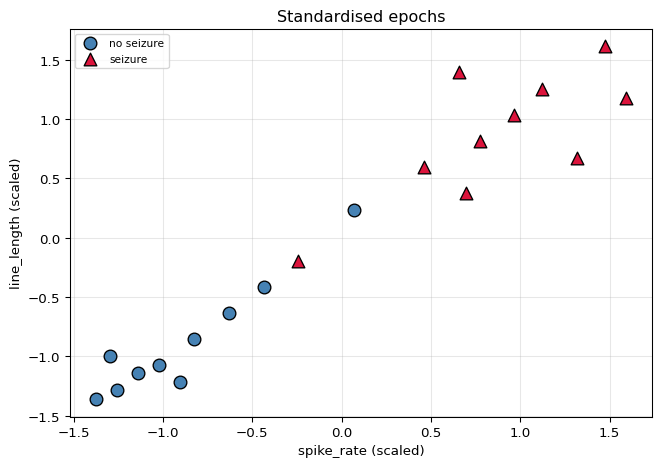

In [3]:
def plot2d(ax=None, scaled=False, title="", legend=True):
    A = Pz if scaled else P
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=(7, 5))
    for c, (col, mk) in enumerate([("steelblue", "o"), ("crimson", "^")]):
        m = t2 == c
        ax.scatter(A[m, 0], A[m, 1], c=col, marker=mk, s=90, edgecolor="k",
                   label=cls_names[c], zorder=3)
    ax.set(xlabel=feat2[0] + (" (scaled)" if scaled else ""),
           ylabel=feat2[1] + (" (scaled)" if scaled else ""), title=title)
    if legend:
        ax.legend(fontsize=8)
    ax.grid(alpha=.3)
    return ax

Pz = (P - P.mean(axis=0)) / P.std(axis=0)
ypm = np.where(t2 == 1, 1, -1)          # SVMs use labels in {-1, +1}

print(f"labels recoded for SVM: {ypm}\n")
print("The +/-1 convention is what makes the constraint y*(w.x + b) >= 1 work for")
print("both classes with a single expression.\n")
plot2d(scaled=True, title="Standardised epochs")
plt.tight_layout(); plt.show()

---
# 2. Margin, and Why It Is $2/\lVert\mathbf{w}\rVert$

The boundary is $\mathbf{w}^\top\mathbf{x} + b = 0$. Fix the scale by requiring the
closest points of each class to satisfy $\mathbf{w}^\top\mathbf{x} + b = \pm 1$ &mdash; this
costs nothing, since $(\mathbf{w}, b)$ can always be rescaled.

The signed distance from a point to the hyperplane is

$$\text{distance} = \frac{\mathbf{w}^\top\mathbf{x} + b}{\lVert\mathbf{w}\rVert}$$

so the two margin planes sit at $\pm 1/\lVert\mathbf{w}\rVert$, and the gap between them is

$$\text{margin} = \frac{2}{\lVert\mathbf{w}\rVert}$$

**Maximising the margin is therefore minimising $\lVert\mathbf{w}\rVert$** &mdash; which is why
the SVM objective looks like a regularisation term with constraints attached.

In [4]:
from sklearn.svm import SVC

lin = SVC(kernel="linear", C=1.0).fit(Pz, t2)
w_sv = lin.coef_[0]
b_sv = float(lin.intercept_[0])

print(f"w = {np.round(w_sv, 6)}     b = {b_sv:+.6f}")
print(f"||w|| = sqrt({w_sv[0]:.4f}^2 + {w_sv[1]:.4f}^2) = {np.linalg.norm(w_sv):.6f}")
print(f"margin = 2 / ||w|| = 2 / {np.linalg.norm(w_sv):.6f} = "
      f"{2/np.linalg.norm(w_sv):.6f}\n")

f_x = Pz @ w_sv + b_sv
print(f"{'id':>6}  {'w.x + b':>10}  {'y':>4}  {'y(w.x+b)':>10}  {'dist to plane':>14}  {'status':>16}")
print("-" * 72)
for i in np.argsort(np.abs(f_x)):
    marg = ypm[i] * f_x[i]
    dist = f_x[i] / np.linalg.norm(w_sv)
    if marg < 0:
        st = "MISCLASSIFIED"
    elif marg <= 1 + 1e-6:
        st = "support vector"
    else:
        st = "safely outside"
    print(f"{ep_ids[i]:>6}  {f_x[i]:>10.5f}  {ypm[i]:>4}  {marg:>10.5f}  "
          f"{dist:>14.5f}  {st:>16}")
print("-" * 72)

print(f"\nsupport vectors found by sklearn: {[ep_ids[i] for i in lin.support_]}")
print(f"that is {len(lin.support_)} of {n2} points - the other "
      f"{n2 - len(lin.support_)} do not affect the solution at all.")

w = [0.8873 0.8112]     b = +0.075223
||w|| = sqrt(0.8873^2 + 0.8112^2) = 1.202211
margin = 2 / ||w|| = 2 / 1.202211 = 1.663602

    id     w.x + b     y    y(w.x+b)   dist to plane            status
------------------------------------------------------------------------
  ep18    -0.30107     1    -0.30107        -0.25043     MISCLASSIFIED
  ep09     0.32864    -1    -0.32864         0.27336     MISCLASSIFIED
  ep08    -0.65054    -1     0.65054        -0.54112    support vector
  ep12     0.96876     1     0.96876         0.80582    support vector
  ep17     1.00000     1     1.00000         0.83180    support vector
  ep05    -1.00000    -1     1.00000        -0.83180    support vector
  ep03    -1.34946    -1     1.34946        -1.12249    safely outside
  ep10     1.42205     1     1.42205         1.18287    safely outside
  ep01    -1.69893    -1     1.69893        -1.41317    safely outside
  ep07    -1.71271    -1     1.71271        -1.42464    safely outside
  ep14     1.7715

### Deleting the non-support vectors changes nothing

This is the claim worth testing directly: refit the SVM using **only** the support
vectors and the boundary should be identical.

In [5]:
sv_idx = lin.support_
lin_sv_only = SVC(kernel="linear", C=1.0).fit(Pz[sv_idx], t2[sv_idx])

print(f"trained on all {n2} points   : w = {np.round(lin.coef_[0], 6)}, "
      f"b = {lin.intercept_[0]:+.6f}")
print(f"trained on {len(sv_idx)} support vectors: w = {np.round(lin_sv_only.coef_[0], 6)}, "
      f"b = {lin_sv_only.intercept_[0]:+.6f}")
print(f"\nsame w? {np.allclose(lin.coef_[0], lin_sv_only.coef_[0], atol=1e-4)}")
print(f"same b? {np.isclose(lin.intercept_[0], lin_sv_only.intercept_[0], atol=1e-4)}")
print(f"same predictions on all {n2} points? "
      f"{np.array_equal(lin.predict(Pz), lin_sv_only.predict(Pz))}")

far = np.setdiff1d(np.arange(n2), sv_idx)
moved = Pz.copy()
moved[far] += np.sign(ypm[far])[:, None] * 2.0        # push them further away
lin_moved = SVC(kernel="linear", C=1.0).fit(moved, t2)
print(f"\nnow move every NON-support vector 2 units further from the boundary:")
print(f"   w before {np.round(lin.coef_[0], 5)}  ->  after {np.round(lin_moved.coef_[0], 5)}")
print(f"   unchanged? {np.allclose(lin.coef_[0], lin_moved.coef_[0], atol=1e-3)}")
print(f"\nThat is the defining property of an SVM: the solution is determined by a")
print(f"handful of boundary cases, not by the bulk of the data.")

trained on all 20 points   : w = [0.8873 0.8112], b = +0.075223
trained on 6 support vectors: w = [0.8873 0.8112], b = +0.075223

same w? True
same b? True
same predictions on all 20 points? True

now move every NON-support vector 2 units further from the boundary:
   w before [0.8873 0.8112]  ->  after [0.8873 0.8112]
   unchanged? True

That is the defining property of an SVM: the solution is determined by a
handful of boundary cases, not by the bulk of the data.


---
# 3. Soft Margin and $C$

Our data is not separable &mdash; two epochs sit on the wrong side. A hard margin has no
feasible solution at all, so slack variables $\xi_i \ge 0$ allow violations at a price:

$$\min_{\mathbf{w},b,\xi} \;\; \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \xi_i
\qquad\text{s.t.}\qquad y_i(\mathbf{w}^\top\mathbf{x}_i+b) \ge 1 - \xi_i$$

Equivalently, in unconstrained form with the **hinge loss**:

$$\min_{\mathbf{w},b}\;\; \frac{1}{2}\lVert\mathbf{w}\rVert^2 + C\sum_i \max\big(0,\; 1 - y_i(\mathbf{w}^\top\mathbf{x}_i + b)\big)$$

$C$ sets the exchange rate between margin width and violations:

* **small $C$** &mdash; violations are cheap, so the margin grows wide and more points sit inside it
* **large $C$** &mdash; violations are expensive, so the margin narrows to avoid them (approaching a hard margin)

In [6]:
def hinge_objective(w_, b_, Cv):
    marg = ypm * (Pz @ w_ + b_)
    hinge = np.maximum(0, 1 - marg)
    return 0.5*np.dot(w_, w_) + Cv*hinge.sum(), hinge

print(f"{'C':>8}  {'||w||':>9}  {'margin':>9}  {'#SV':>5}  {'sum slack':>10}  "
      f"{'train acc':>10}  {'objective':>11}")
print("-" * 72)
for Cv in (0.01, 0.1, 1.0, 10.0, 100.0, 1000.0):
    m = SVC(kernel="linear", C=Cv).fit(Pz, t2)
    ww, bb = m.coef_[0], float(m.intercept_[0])
    obj, hinge = hinge_objective(ww, bb, Cv)
    print(f"{Cv:>8.2f}  {np.linalg.norm(ww):>9.4f}  {2/np.linalg.norm(ww):>9.4f}  "
          f"{len(m.support_):>5}  {hinge.sum():>10.4f}  {m.score(Pz, t2):>10.4f}  "
          f"{obj:>11.4f}")
print("-" * 72)
print("\nAs C grows the margin shrinks, the slack shrinks, and fewer points are")
print("support vectors. Small C is the more regularised model.")

print(f"\n\nhinge loss at C = 1, per point:\n")
m1 = SVC(kernel="linear", C=1.0).fit(Pz, t2)
_, hg = hinge_objective(m1.coef_[0], float(m1.intercept_[0]), 1.0)
print(f"{'id':>6}  {'y(w.x+b)':>10}  {'hinge':>9}  {'meaning':>28}")
print("-" * 60)
for i in np.argsort(-hg):
    marg = ypm[i]*(Pz[i] @ m1.coef_[0] + m1.intercept_[0])
    if hg[i] == 0:
        mean = "outside margin, no cost"
    elif marg > 0:
        mean = "inside margin, correct"
    else:
        mean = "on the wrong side"
    print(f"{ep_ids[i]:>6}  {marg:>10.5f}  {hg[i]:>9.5f}  {mean:>28}")
print("-" * 60)
print(f"\ntotal hinge = {hg.sum():.6f}")

       C      ||w||     margin    #SV   sum slack   train acc    objective
------------------------------------------------------------------------
    0.01     0.2482     8.0578     20     13.8393      0.9000       0.1692
    0.10     0.6917     2.8914     10      4.6859      0.9000       0.7078
    1.00     1.2022     1.6636      6      3.0104      0.9000       3.7331
   10.00     1.5731     1.2714      4      2.7568      0.9000      28.8058
  100.00     3.1708     0.6307      5      2.6343      0.9000     268.4573
 1000.00     3.1749     0.6299      5      2.6346      0.9000    2639.6695
------------------------------------------------------------------------

As C grows the margin shrinks, the slack shrinks, and fewer points are
support vectors. Small C is the more regularised model.


hinge loss at C = 1, per point:

    id    y(w.x+b)      hinge                       meaning
------------------------------------------------------------
  ep09    -0.32864    1.32864             on 

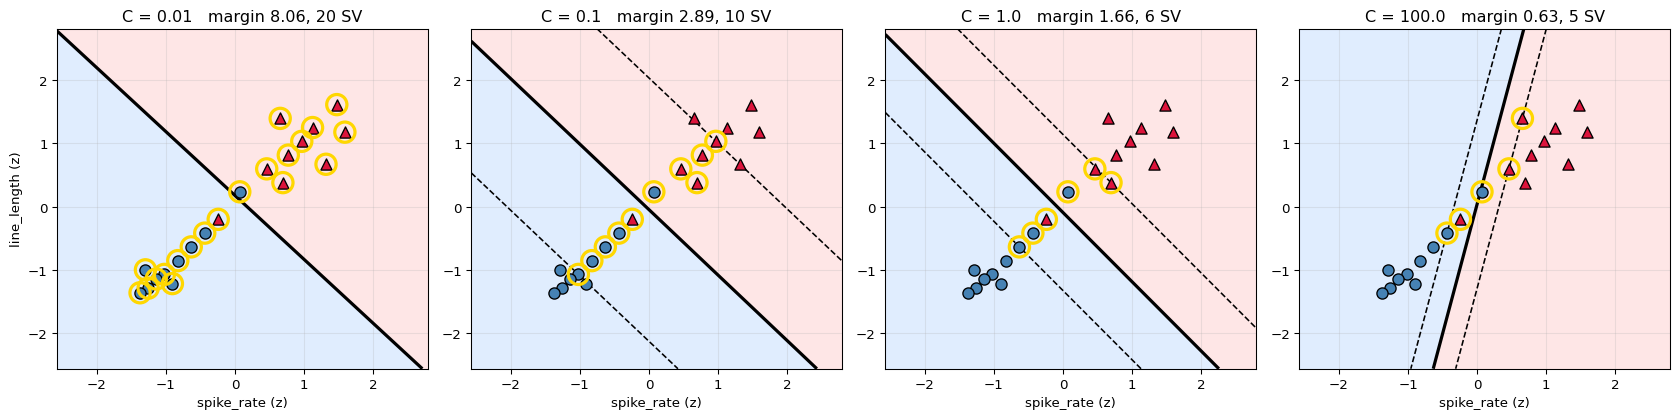

Gold circles are support vectors. Dashed lines are the margin boundaries.
Small C: wide margin, many support vectors, some violations tolerated.
Large C: narrow margin, few support vectors, violations avoided.


In [7]:
gx, gy = np.meshgrid(np.linspace(Pz[:,0].min()-1.2, Pz[:,0].max()+1.2, 300),
                     np.linspace(Pz[:,1].min()-1.2, Pz[:,1].max()+1.2, 300))
G = np.column_stack([gx.ravel(), gy.ravel()])

Cs = [0.01, 0.1, 1.0, 100.0]
fig, axes = plt.subplots(1, len(Cs), figsize=(4.4*len(Cs), 4.5))
for ax, Cv in zip(axes, Cs):
    m = SVC(kernel="linear", C=Cv).fit(Pz, t2)
    dec = m.decision_function(G).reshape(gx.shape)
    ax.contourf(gx, gy, dec > 0, levels=[-.5,.5,1.5], colors=["#dbeafe","#fee2e2"], alpha=.85)
    ax.contour(gx, gy, dec, levels=[-1, 0, 1], colors="k",
               linestyles=["--", "-", "--"], linewidths=[1.2, 2.4, 1.2])
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        mm = t2 == c
        ax.scatter(Pz[mm,0], Pz[mm,1], c=col, marker=mk, s=70, edgecolor="k", zorder=3)
    ax.scatter(Pz[m.support_,0], Pz[m.support_,1], s=230, facecolors="none",
               edgecolors="gold", linewidths=2.4, zorder=4)
    ax.set(title=f"C = {Cv}   margin {2/np.linalg.norm(m.coef_[0]):.2f}, "
                 f"{len(m.support_)} SV", xlabel=feat2[0]+" (z)")
    ax.grid(alpha=.25)
axes[0].set_ylabel(feat2[1]+" (z)")
plt.tight_layout(); plt.show()

print("Gold circles are support vectors. Dashed lines are the margin boundaries.")
print("Small C: wide margin, many support vectors, some violations tolerated.")
print("Large C: narrow margin, few support vectors, violations avoided.")

---
# 4. The Dual, and Where Kernels Come From

Introducing Lagrange multipliers $\alpha_i \ge 0$ for the constraints and eliminating
$\mathbf{w}$ and $b$ gives the **dual problem**:

$$\max_{\alpha} \;\; \sum_i \alpha_i - \frac{1}{2}\sum_{i,j}\alpha_i\alpha_j y_i y_j \,\mathbf{x}_i^\top\mathbf{x}_j
\qquad\text{s.t.}\qquad 0 \le \alpha_i \le C, \;\; \sum_i \alpha_i y_i = 0$$

and the solution is recovered as

$$\mathbf{w} = \sum_i \alpha_i y_i \mathbf{x}_i$$

Two things are now visible that were hidden in the original form:

* **$\alpha_i = 0$ for every non-support vector.** The sum runs only over the few points
  on or inside the margin.
* **The data appears only as $\mathbf{x}_i^\top\mathbf{x}_j$.** Nothing else. Replace that
  inner product with any valid kernel $K(\mathbf{x}_i,\mathbf{x}_j)$ and the algorithm is
  unchanged &mdash; this is the *kernel trick*.

In [8]:
alpha_y = lin.dual_coef_[0]                 # sklearn stores alpha_i * y_i
alphas = np.abs(alpha_y)

print(f"sklearn returns {len(alpha_y)} dual coefficients (alpha_i * y_i):\n")
print(f"{'id':>6}  {'y':>4}  {'alpha*y':>11}  {'alpha':>10}  {'at bound C?':>12}")
print("-" * 50)
for k, i in enumerate(lin.support_):
    at_bound = "yes (C=1)" if np.isclose(alphas[k], 1.0, atol=1e-6) else "no"
    print(f"{ep_ids[i]:>6}  {ypm[i]:>4}  {alpha_y[k]:>11.6f}  {alphas[k]:>10.6f}  "
          f"{at_bound:>12}")
print("-" * 50)

print(f"\nconstraint check: sum of alpha_i * y_i = {alpha_y.sum():+.3e}   "
      f"(must be 0): {np.isclose(alpha_y.sum(), 0, atol=1e-6)}")

w_dual = (alpha_y[:, None] * Pz[lin.support_]).sum(axis=0)
print(f"\nrecovering w from the dual:  w = sum_i alpha_i y_i x_i\n")
for j, f in enumerate(feat2):
    terms = " + ".join(f"({alpha_y[k]:+.4f})*({Pz[i,j]:+.4f})"
                       for k, i in enumerate(lin.support_))
    print(f"   w[{j}] ({f}):")
    print(f"      {terms}")
    print(f"      = {w_dual[j]:+.6f}   |  sklearn: {w_sv[j]:+.6f}   "
          f"MATCH: {np.isclose(w_dual[j], w_sv[j])}")
print(f"\nfull w MATCH: {np.allclose(w_dual, w_sv)}")
print(f"\nEvery non-support vector has alpha = 0 and contributes nothing to this sum.")

sklearn returns 6 dual coefficients (alpha_i * y_i):

    id     y      alpha*y       alpha   at bound C?
--------------------------------------------------
  ep05    -1    -0.227861    0.227861            no
  ep08    -1    -1.000000    1.000000     yes (C=1)
  ep09    -1    -1.000000    1.000000     yes (C=1)
  ep12     1     1.000000    1.000000     yes (C=1)
  ep17     1     0.227861    0.227861            no
  ep18     1     1.000000    1.000000     yes (C=1)
--------------------------------------------------

constraint check: sum of alpha_i * y_i = +0.000e+00   (must be 0): True

recovering w from the dual:  w = sum_i alpha_i y_i x_i

   w[0] (spike_rate):
      (-0.2279)*(-0.6319) + (-1.0000)*(-0.4369) + (-1.0000)*(+0.0702) + (+1.0000)*(+0.4603) + (+0.2279)*(+0.6943) + (+1.0000)*(-0.2418)
      = +0.887281   |  sklearn: +0.887281   MATCH: True
   w[1] (line_length):
      (-0.2279)*(-0.6343) + (-1.0000)*(-0.4168) + (-1.0000)*(+0.2356) + (+1.0000)*(+0.5981) + (+0.2279)*(+0.3806)

---
# 5. Kernels

A kernel computes an inner product in some feature space $\phi$ **without ever building
$\phi(\mathbf{x})$**:

$$K(\mathbf{a},\mathbf{b}) = \phi(\mathbf{a})^\top\phi(\mathbf{b})$$

| Kernel | Formula | Feature space |
|---|---|---|
| Linear | $\mathbf{a}^\top\mathbf{b}$ | the original one |
| Polynomial | $(\gamma\,\mathbf{a}^\top\mathbf{b} + r)^d$ | all monomials up to degree $d$ |
| RBF / Gaussian | $\exp(-\gamma\lVert\mathbf{a}-\mathbf{b}\rVert^2)$ | **infinite-dimensional** |

The RBF case is the striking one: an infinite-dimensional feature map, evaluated in two
arithmetic operations. The explicit expansion below shows why the polynomial kernel works,
and by extension why the trick is legitimate.

In [9]:
a, b = Pz[0], Pz[10]
print(f"take two epochs:  a = {ep_ids[0]} = {np.round(a,4)}")
print(f"                  b = {ep_ids[10]} = {np.round(b,4)}\n")

print("POLYNOMIAL kernel, degree 2, gamma = 1, r = 1")
print("-" * 60)
k_poly = (a @ b + 1.0) ** 2
print(f"   K(a,b) = (a.b + 1)^2 = ({a @ b:.6f} + 1)^2 = {k_poly:.6f}")

def phi2(x):
    """The explicit feature map for (a.b + 1)^2 in 2-D."""
    x1, x2 = x
    return np.array([1.0, np.sqrt(2)*x1, np.sqrt(2)*x2,
                     x1**2, x2**2, np.sqrt(2)*x1*x2])

pa, pb = phi2(a), phi2(b)
print(f"\n   the explicit 6-dim map phi(x) = [1, sqrt2*x1, sqrt2*x2, x1^2, x2^2, sqrt2*x1*x2]")
print(f"   phi(a) = {np.round(pa, 5)}")
print(f"   phi(b) = {np.round(pb, 5)}")
print(f"\n   phi(a).phi(b) = {expand(pa, pb, per_line=3)}")
print(f"                 = {pa @ pb:.6f}")
print(f"   K(a,b)        = {k_poly:.6f}")
print(f"   MATCH: {np.isclose(pa @ pb, k_poly)}")
print(f"\n   The kernel computed in 2 operations what the explicit map needed 6")
print(f"   dimensions for. In degree 3 with 10 features the map has 286 terms;")
print(f"   the kernel is still one dot product and one power.\n")

print("RBF kernel, gamma = 0.5")
print("-" * 60)
gam = 0.5
d2 = np.sum((a-b)**2)
k_rbf = np.exp(-gam * d2)
print(f"   ||a - b||^2 = {expand(a-b, a-b, per_line=2)}")
print(f"               = {d2:.6f}")
print(f"   K(a,b) = exp(-{gam} * {d2:.6f}) = {k_rbf:.8f}")
print(f"\n   K depends ONLY on the distance, so it acts as a similarity that decays")
print(f"   with separation. K(x,x) = 1 always, and K -> 0 for distant points.")

take two epochs:  a = ep00 = [-1.256  -1.2867]
                  b = ep10 = [0.7723 0.8155]

POLYNOMIAL kernel, degree 2, gamma = 1, r = 1
------------------------------------------------------------
   K(a,b) = (a.b + 1)^2 = (-2.019426 + 1)^2 = 1.039229

   the explicit 6-dim map phi(x) = [1, sqrt2*x1, sqrt2*x2, x1^2, x2^2, sqrt2*x1*x2]
   phi(a) = [ 1.     -1.7762 -1.8197  1.5775  1.6557  2.2856]
   phi(b) = [1.     1.0922 1.1534 0.5965 0.6651 0.8908]

   phi(a).phi(b) = (+1.0000)*(+1.0000) + (-1.7762)*(+1.0922) + (-1.8197)*(+1.1534) + 
      (+1.5775)*(+0.5965) + (+1.6557)*(+0.6651) + (+2.2856)*(+0.8908)
                 = 1.039229
   K(a,b)        = 1.039229
   MATCH: True

   The kernel computed in 2 operations what the explicit map needed 6
   dimensions for. In degree 3 with 10 features the map has 286 terms;
   the kernel is still one dot product and one power.

RBF kernel, gamma = 0.5
------------------------------------------------------------
   ||a - b||^2 = (-2.0283)*(-2.0

In [10]:
def kernel_matrix(A, kind, gamma=0.5, degree=3, coef0=1.0):
    if kind == "linear":
        return A @ A.T
    if kind == "poly":
        return (gamma * (A @ A.T) + coef0) ** degree
    sq = np.sum(A**2, axis=1)
    return np.exp(-gamma * (sq[:, None] + sq[None, :] - 2 * A @ A.T))

Ksub = kernel_matrix(Pz, "rbf", gamma=0.5)[:6, :6]
show_matrix(Ksub, "RBF kernel matrix (first 6 epochs)", rows=ep_ids[:6],
            cols=ep_ids[:6], fmt="{:8.5f}")
print(f"\n   diagonal is all 1 (a point is maximally similar to itself): "
      f"{np.allclose(np.diag(kernel_matrix(Pz,'rbf')), 1.0)}")
print(f"   symmetric: {np.allclose(kernel_matrix(Pz,'rbf'), kernel_matrix(Pz,'rbf').T)}")
ev = np.linalg.eigvalsh(kernel_matrix(Pz, "rbf"))
print(f"   smallest eigenvalue = {ev.min():.3e}  -> positive semi-definite: "
      f"{ev.min() > -1e-8}")
print(f"\n   Positive semi-definiteness (Mercer's condition) is exactly what")
print(f"   guarantees some feature space phi exists for this kernel.")

RBF kernel matrix (first 6 epochs) (6, 6) =
                   ep00      ep01      ep02      ep03      ep04      ep05
         ep00 |  1.00000   0.95025   0.99057   0.82974   0.98279   0.66526
         ep01 |  0.95025   1.00000   0.90153   0.95823   0.99057   0.84310
         ep02 |  0.99057   0.90153   1.00000   0.75741   0.95025   0.58427
         ep03 |  0.82974   0.95823   0.75741   1.00000   0.91327   0.95823
         ep04 |  0.98279   0.99057   0.95025   0.91327   1.00000   0.77312
         ep05 |  0.66526   0.84310   0.58427   0.95823   0.77312   1.00000

   diagonal is all 1 (a point is maximally similar to itself): True
   symmetric: True
   smallest eigenvalue = 7.650e-08  -> positive semi-definite: True

   Positive semi-definiteness (Mercer's condition) is exactly what
   guarantees some feature space phi exists for this kernel.


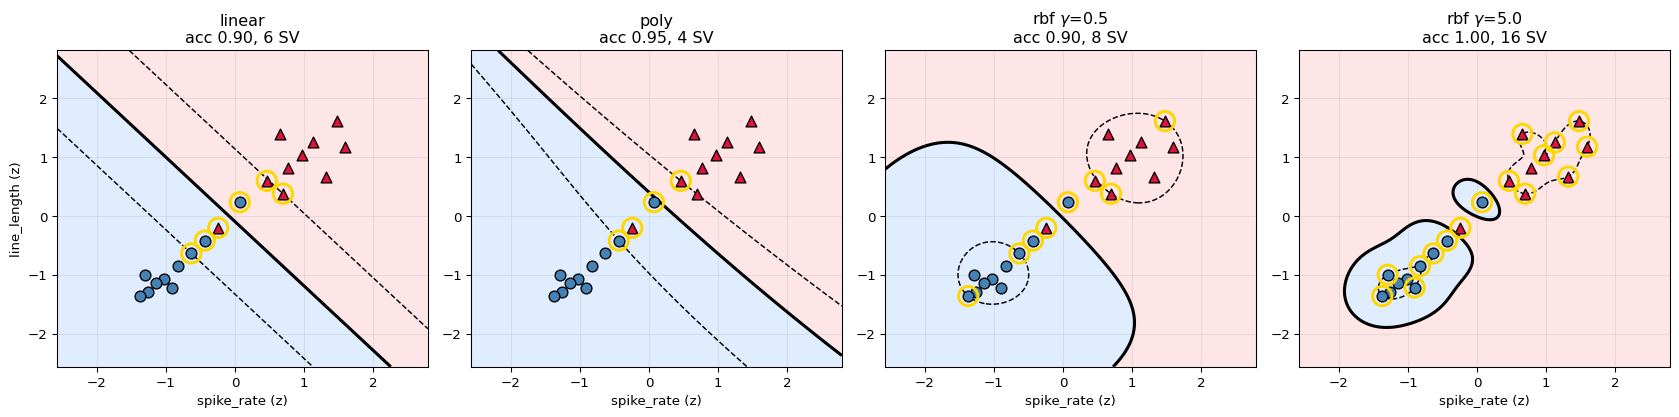

                kernel   train acc    #SV
------------------------------------------
                linear      0.9000      6
                  poly      0.9500      4
         rbf gamma=0.5      0.9000      8
         rbf gamma=5.0      1.0000     16
------------------------------------------

gamma = 5 reaches 100% training accuracy by wrapping tight bubbles around
the two awkward epochs. That is memorisation, not generalisation - the
classic RBF failure mode when gamma is too large.


In [11]:
kernels = [("linear", {}), ("poly", dict(degree=3, gamma=1.0, coef0=1.0)),
           ("rbf", dict(gamma=0.5)), ("rbf", dict(gamma=5.0))]
fig, axes = plt.subplots(1, len(kernels), figsize=(4.4*len(kernels), 4.5))
for ax, (kn, kw) in zip(axes, kernels):
    m = SVC(kernel=kn, C=1.0, **kw).fit(Pz, t2)
    dec = m.decision_function(G).reshape(gx.shape)
    ax.contourf(gx, gy, dec > 0, levels=[-.5,.5,1.5], colors=["#dbeafe","#fee2e2"], alpha=.85)
    ax.contour(gx, gy, dec, levels=[-1,0,1], colors="k",
               linestyles=["--","-","--"], linewidths=[1.1,2.3,1.1])
    for c, (col, mk) in enumerate([("steelblue","o"), ("crimson","^")]):
        mm = t2 == c
        ax.scatter(Pz[mm,0], Pz[mm,1], c=col, marker=mk, s=65, edgecolor="k", zorder=3)
    ax.scatter(Pz[m.support_,0], Pz[m.support_,1], s=210, facecolors="none",
               edgecolors="gold", linewidths=2.2, zorder=4)
    lab = kn + (f" $\\gamma$={kw['gamma']}" if kn=="rbf" else "")
    ax.set(title=f"{lab}\nacc {m.score(Pz,t2):.2f}, {len(m.support_)} SV",
           xlabel=feat2[0]+" (z)")
    ax.grid(alpha=.25)
axes[0].set_ylabel(feat2[1]+" (z)")
plt.tight_layout(); plt.show()

print(f"{'kernel':>22}  {'train acc':>10}  {'#SV':>5}")
print("-" * 42)
for kn, kw in kernels:
    m = SVC(kernel=kn, C=1.0, **kw).fit(Pz, t2)
    lab = kn + (f" gamma={kw['gamma']}" if kn=="rbf" else "")
    print(f"{lab:>22}  {m.score(Pz,t2):>10.4f}  {len(m.support_):>5}")
print("-" * 42)
print("\ngamma = 5 reaches 100% training accuracy by wrapping tight bubbles around")
print("the two awkward epochs. That is memorisation, not generalisation - the")
print("classic RBF failure mode when gamma is too large.")

---
# 6. Predicting Through the Kernel

Once kernelised, prediction never uses $\mathbf{w}$ &mdash; it may not even exist in finite
dimensions. Instead:

$$f(\mathbf{x}) = \sum_{i \in SV} \alpha_i y_i K(\mathbf{x}_i, \mathbf{x}) + b,
\qquad \hat{y} = \operatorname{sign} f(\mathbf{x})$$

This is why a kernel SVM must keep its support vectors: they are the model.

In [12]:
rbf = SVC(kernel="rbf", C=1.0, gamma=0.5).fit(Pz, t2)
dc = rbf.dual_coef_[0]
svs = rbf.support_vectors_
b_r = float(rbf.intercept_[0])

xq = Pz[3]
print(f"classifying {ep_ids[3]} = {np.round(xq, 4)}  (true class {t2[3]})\n")
kv = np.exp(-0.5 * np.sum((svs - xq)**2, axis=1))

print(f"{'SV':>6}  {'alpha*y':>10}  {'K(sv, x)':>11}  {'product':>11}")
print("-" * 44)
for k, i in enumerate(rbf.support_):
    print(f"{ep_ids[i]:>6}  {dc[k]:>10.5f}  {kv[k]:>11.6f}  {dc[k]*kv[k]:>11.6f}")
print("-" * 44)
tot = float(dc @ kv)
print(f"{'sum':>6}  {'':>10}  {'':>11}  {tot:>11.6f}")
print(f"\nf(x) = {tot:.6f} + b({b_r:+.6f}) = {tot + b_r:+.6f}")
print(f"sklearn decision_function      = {rbf.decision_function(xq[None,:])[0]:+.6f}")
print(f"MATCH: {np.isclose(tot + b_r, rbf.decision_function(xq[None,:])[0])}")
print(f"\nprediction = sign({tot+b_r:+.4f}) -> class "
      f"{1 if tot+b_r > 0 else 0},  true {t2[3]}")

mine_all = np.array([1 if (float(np.exp(-0.5*np.sum((svs-Pz[i])**2,axis=1)) @ dc) + b_r) > 0
                     else 0 for i in range(n2)])
print(f"\nall {n2} predictions computed by hand MATCH sklearn: "
      f"{np.array_equal(mine_all, rbf.predict(Pz))}")

classifying ep03 = [-0.8269 -0.8518]  (true class 0)

    SV     alpha*y     K(sv, x)      product
--------------------------------------------
  ep02    -0.58915     0.757406    -0.446223
  ep05    -0.49117     0.958231    -0.470658
  ep08    -1.00000     0.843102    -0.843102
  ep09    -1.00000     0.370227    -0.370227
  ep12     1.00000     0.152669     0.152669
  ep13     0.48522     0.003394     0.001647
  ep17     0.59510     0.147128     0.087556
  ep18     1.00000     0.681131     0.681131
--------------------------------------------
   sum                             -1.207206

f(x) = -1.207206 + b(+0.076839) = -1.130367
sklearn decision_function      = -1.130367
MATCH: True

prediction = sign(-1.1304) -> class 0,  true 0

all 20 predictions computed by hand MATCH sklearn: True


---
# 7. Checking Against scikit-learn

In [13]:
print("linear SVM, dual solution")
print("-" * 56)
print(f"w from dual sum : {np.round(w_dual, 8)}")
print(f"w from sklearn  : {np.round(w_sv, 8)}")
print(f"MATCH: {np.allclose(w_dual, w_sv)}")

f_mine = Pz @ w_dual + b_sv
print(f"\ndecision_function MATCH: "
      f"{np.allclose(f_mine, lin.decision_function(Pz))}")
print(f"predictions MATCH      : "
      f"{np.array_equal((f_mine > 0).astype(int), lin.predict(Pz))}")

print(f"\n\nhinge-loss objective vs sklearn's own solution")
print("-" * 56)
for Cv in (0.1, 1.0, 10.0):
    m = SVC(kernel="linear", C=Cv).fit(Pz, t2)
    obj_sk, _ = hinge_objective(m.coef_[0], float(m.intercept_[0]), Cv)
    rng_p = np.random.default_rng(0)
    better = 0
    for _ in range(4000):
        pert_w = m.coef_[0] + rng_p.normal(scale=.05, size=2)
        pert_b = float(m.intercept_[0]) + rng_p.normal(scale=.05)
        if hinge_objective(pert_w, pert_b, Cv)[0] < obj_sk - 1e-9:
            better += 1
    print(f"C = {Cv:>6}: objective {obj_sk:.6f}, "
          f"random perturbations that beat it: {better}/4000")
print("-" * 56)
print("\nNo nearby perturbation improves the objective, which is what we expect")
print("at the optimum of a convex problem.")

print(f"\n\nkernel matrix computed by hand vs sklearn")
print("-" * 56)
from sklearn.metrics.pairwise import rbf_kernel, polynomial_kernel
print(f"RBF  MATCH: {np.allclose(kernel_matrix(Pz,'rbf',gamma=0.5), rbf_kernel(Pz, gamma=0.5))}")
print(f"poly MATCH: {np.allclose(kernel_matrix(Pz,'poly',gamma=1.0,degree=3,coef0=1.0), polynomial_kernel(Pz, degree=3, gamma=1.0, coef0=1.0))}")

linear SVM, dual solution
--------------------------------------------------------
w from dual sum : [0.8873 0.8112]
w from sklearn  : [0.8873 0.8112]
MATCH: True

decision_function MATCH: True
predictions MATCH      : True


hinge-loss objective vs sklearn's own solution
--------------------------------------------------------
C =    0.1: objective 0.707809, random perturbations that beat it: 0/4000
C =    1.0: objective 3.733068, random perturbations that beat it: 0/4000
C =   10.0: objective 28.805766, random perturbations that beat it: 0/4000
--------------------------------------------------------

No nearby perturbation improves the objective, which is what we expect
at the optimum of a convex problem.


kernel matrix computed by hand vs sklearn
--------------------------------------------------------
RBF  MATCH: True
poly MATCH: True


---
# 8. Summary

| Concept | Formula |
|---|---|
| Margin | $2/\lVert\mathbf{w}\rVert$ |
| Primal | $\tfrac12\lVert\mathbf{w}\rVert^2 + C\sum_i\max(0, 1-y_i f(\mathbf{x}_i))$ |
| Dual | $\sum_i\alpha_i - \tfrac12\sum_{i,j}\alpha_i\alpha_j y_iy_j K(\mathbf{x}_i,\mathbf{x}_j)$ |
| Recover $\mathbf{w}$ | $\sum_i \alpha_i y_i \mathbf{x}_i$ |
| Predict | $\operatorname{sign}\big(\sum_{i\in SV}\alpha_i y_i K(\mathbf{x}_i,\mathbf{x}) + b\big)$ |
| Support vector | $\alpha_i > 0$, i.e. on or inside the margin |
| $C$ | large = narrow margin, few violations |
| $\gamma$ (RBF) | large = tight, local bubbles = overfitting |

**The one idea:** write the problem so the data appears only as inner products, and every
inner product becomes a free choice. That is the kernel trick, and it turns a linear
classifier into a family that includes infinite-dimensional feature spaces.

**The practical cost:** the dual is $O(n^2)$ to $O(n^3)$ in the number of samples, and the
kernel matrix is $n \times n$. SVMs are excellent up to tens of thousands of rows and
impractical at millions &mdash; which is precisely the range where the gradient-boosted trees
in this series take over.

**What is deliberately left out:** the KKT conditions and how $b$ is recovered from them,
the SMO algorithm that actually solves the dual, multi-class strategies (one-vs-one,
one-vs-rest), probability calibration via Platt scaling, and the $\nu$-SVM
parameterisation.